In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Formation plot

[[ 0.     0.     0.375  0.75  -0.375 -0.75  -0.5    0.5  ]
 [ 0.    -0.45  -0.4   -0.25  -0.4   -0.25   0.4    0.4  ]]


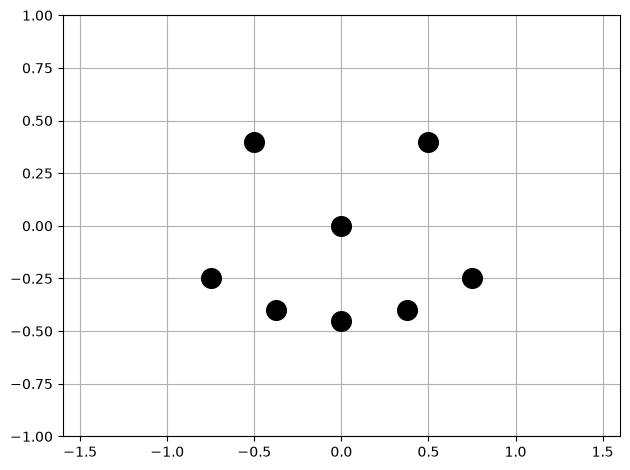

In [80]:
x = np.array([[0,0,0.375,0.75,-0.375,-0.75,-0.5,0.5],
              [0,-0.45,-0.4,-0.25,-0.4,-0.25,0.4,0.4]])
print(x)
fig, ax = plt.subplots(1,1,layout='tight')
ax.grid()
ax.set_axisbelow(True)
ax.set_xlim(-1.6,1.6)
ax.set_ylim(-1,1)
for i in range(len(x[0,:])):
    ax.scatter(x[0,i],x[1,i],s=200,color='black')
plt.show()

# Comm. graph

[[ 0.5    0.    -0.5   -0.75  -0.375  0.     0.375  0.75 ]
 [ 0.4    0.     0.4   -0.25  -0.4   -0.45  -0.4   -0.25 ]]
[[0. 1. 0. 0. 0. 0. 1. 1.]
 [1. 0. 1. 0. 0. 1. 1. 0.]
 [0. 1. 0. 1. 1. 1. 0. 0.]
 [0. 0. 1. 0. 1. 0. 0. 1.]
 [0. 0. 1. 1. 0. 1. 0. 0.]
 [0. 1. 1. 0. 1. 0. 1. 0.]
 [1. 1. 0. 0. 0. 1. 0. 1.]
 [1. 0. 0. 1. 0. 0. 1. 0.]]
[[0.         0.64031242 0.         0.         0.         0.
  0.80970674 0.69641941]
 [0.64031242 0.         0.64031242 0.         0.         0.45
  0.5482928  0.        ]
 [0.         0.64031242 0.         0.69641941 0.80970674 0.98615415
  0.         0.        ]
 [0.         0.         0.69641941 0.         0.40388736 0.
  0.         1.5       ]
 [0.         0.         0.80970674 0.40388736 0.         0.37831865
  0.         0.        ]
 [0.         0.45       0.98615415 0.         0.37831865 0.
  0.37831865 0.        ]
 [0.80970674 0.5482928  0.         0.         0.         0.37831865
  0.         0.40388736]
 [0.69641941 0.         0.         1.5     

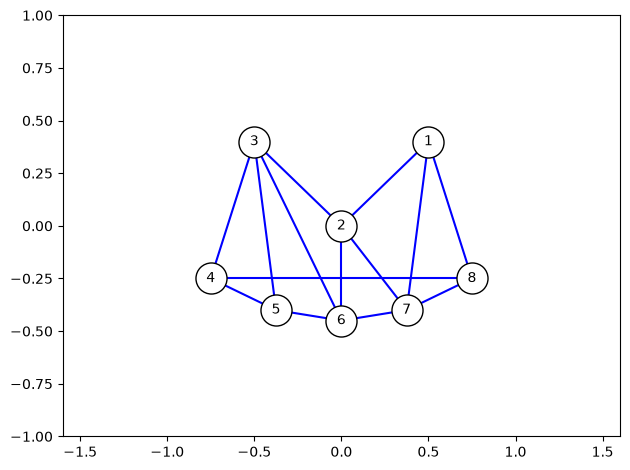

In [90]:
x = np.array([[0.5,0,-0.5,-0.75,-0.375,0,0.375,0.75],
              [0.4,0,0.4,-0.25,-0.4,-0.45,-0.4,-0.25]])
print(x)
adjacency_mat = np.zeros((x.shape[1],x.shape[1]))
distance_mat = np.zeros((x.shape[1],x.shape[1]))
for i in range(-1,len(adjacency_mat)-1):
    adjacency_mat[i,i+1] = 1
adjacency_mat[0,6] = 1
adjacency_mat[1,5] = 1; adjacency_mat[1,6] = 1
adjacency_mat[2,4] = 1; adjacency_mat[2,5] = 1
adjacency_mat[3,7] = 1
adjacency_mat = adjacency_mat + adjacency_mat.transpose()
print(adjacency_mat)

fig, ax = plt.subplots(1,1,layout='tight')
ax.set_xlim(-1.6,1.6)
ax.set_ylim(-1,1)
for i in range(adjacency_mat.shape[0]):
    for j in range(i,adjacency_mat.shape[1]):
        if adjacency_mat[i,j] == 1:
            distance_mat[i,j] = np.linalg.norm(x[:,i]-x[:,j])
            ax.plot([x[0,i],x[0,j]],[x[1,i],x[1,j]],zorder=1,color='blue')
distance_mat = distance_mat + distance_mat.transpose()
for i in range(x.shape[1]):
    ax.scatter(x[0,i],x[1,i],s=500,facecolors='white',edgecolors='black',zorder=2)
    ax.text(x[0,i],x[1,i],s=str(i+1),ha='center',va='center')
print(distance_mat)
plt.show()


## Laplacian

In [91]:
L = np.diag(np.sum(adjacency_mat, axis=1)) - adjacency_mat
print(L)

[[ 3. -1.  0.  0.  0.  0. -1. -1.]
 [-1.  4. -1.  0.  0. -1. -1.  0.]
 [ 0. -1.  4. -1. -1. -1.  0.  0.]
 [ 0.  0. -1.  3. -1.  0.  0. -1.]
 [ 0.  0. -1. -1.  3. -1.  0.  0.]
 [ 0. -1. -1.  0. -1.  4. -1.  0.]
 [-1. -1.  0.  0.  0. -1.  4. -1.]
 [-1.  0.  0. -1.  0.  0. -1.  3.]]
